# Exploratory Data Analysis - IBM Test Data

This notebook performs exploratory data analysis on the IBM test data available in both Parquet and CSV formats.

## 1. Import Required Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', None)

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Data from Both Sources

In [6]:
# Define file paths
parquet_path = '/Users/abhilashamangal/Documents/2026/Github/ShareThis-Predictive-Multilabel-Classification/data/ibm_test_data.parquet'
csv_path = '/Users/abhilashamangal/Documents/2026/Github/ShareThis-Predictive-Multilabel-Classification/data/ibm_test_data.csv'

# Load Parquet file
print("Loading Parquet file...")
df_parquet = pd.read_parquet(parquet_path)
print(f"Parquet file loaded: {df_parquet.shape[0]} rows, {df_parquet.shape[1]} columns")

# Load CSV file
#print("\nLoading CSV file...")
#df_csv = pd.read_csv(csv_path)
#print(f"CSV file loaded: {df_csv.shape[0]} rows, {df_csv.shape[1]} columns")

Loading Parquet file...
Parquet file loaded: 17275 rows, 2 columns


## 3. Compare Data Sources

In [9]:
# Check if both files contain the same data
print("=" * 80)
print("DATA SOURCE COMPARISON")
print("=" * 80)

print(f"\nParquet shape: {df_parquet.shape}")
#print(f"CSV shape: {df_csv.shape}")

#print(f"\nAre shapes identical? {df_parquet.shape == df_csv.shape}")

# Check if column names match
#print(f"\nColumn names match? {list(df_parquet.columns) == list(df_csv.columns)}")
df = df_parquet
print("\n✓ Using Parquet data for further analysis")

DATA SOURCE COMPARISON

Parquet shape: (17275, 2)

✓ Using Parquet data for further analysis


## 4. Basic Dataset Information

In [10]:
print("=" * 80)
print("DATASET OVERVIEW")
print("=" * 80)

print(f"\nDataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"\nMemory Usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\n" + "=" * 80)
print("COLUMN INFORMATION")
print("=" * 80)
df.info()

DATASET OVERVIEW

Dataset Shape: 17,275 rows × 2 columns

Memory Usage: 66.77 MB

COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17275 entries, 0 to 17274
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   text_id  17275 non-null  object
 1   text     17275 non-null  object
dtypes: object(2)
memory usage: 270.1+ KB


In [11]:
# Display first few rows
print("\n" + "=" * 80)
print("FIRST 5 ROWS")
print("=" * 80)
display(df.head())


FIRST 5 ROWS


,text_id,text
0,1138,Embark on a seamless journey with our tours fr...
1,1181,We’re living in hotels full-time at the moment...
2,1274,Scary | Yo Gabba Gabba Wiki | Fandom \n Yo Gab...
3,1291,"The grandfather’s sperm DNA changed its shape,..."
4,1594,"Ryder Korczak's salary is $867,500 and his cap..."


In [12]:
# Display last few rows
print("\n" + "=" * 80)
print("LAST 5 ROWS")
print("=" * 80)
display(df.tail())


LAST 5 ROWS


,text_id,text
17270,51539609028,Each chapter in the 2023 SHOT Annual Report is...
17271,51539609160,Large Trophy Board is a Decoration in Raft. \n...
17272,51539609419,Properly draining a plumbing system is a cruci...
17273,51539610281,Scooby-Doo! and the Halloween Hotel Haunt is a...
17274,8589936912,"Southern Arizona’s monsoon is in full effect, ..."


## 5. Statistical Summary

In [13]:
print("=" * 80)
print("STATISTICAL SUMMARY - NUMERICAL COLUMNS")
print("=" * 80)
display(df.describe())

STATISTICAL SUMMARY - NUMERICAL COLUMNS


,text_id,text
count,17275,17275
unique,17275,17275
top,1138,Embark on a seamless journey with our tours fr...
freq,1,1


In [14]:
# Statistical summary for object/categorical columns
print("\n" + "=" * 80)
print("STATISTICAL SUMMARY - CATEGORICAL COLUMNS")
print("=" * 80)
display(df.describe(include=['object']))


STATISTICAL SUMMARY - CATEGORICAL COLUMNS


,text_id,text
count,17275,17275
unique,17275,17275
top,1138,Embark on a seamless journey with our tours fr...
freq,1,1


## 6. Missing Values Analysis

In [15]:
print("=" * 80)
print("MISSING VALUES ANALYSIS")
print("=" * 80)

missing_data = pd.DataFrame({
    'Column': df.columns,
    'Missing_Count': df.isnull().sum().values,
    'Missing_Percentage': (df.isnull().sum().values / len(df) * 100).round(2)
})

missing_data = missing_data[missing_data['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)

if len(missing_data) > 0:
    display(missing_data)
    
    # Visualize missing values
    plt.figure(figsize=(12, 6))
    plt.bar(missing_data['Column'], missing_data['Missing_Percentage'])
    plt.xlabel('Columns')
    plt.ylabel('Missing Percentage (%)')
    plt.title('Missing Values by Column')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("\n✓ No missing values found in the dataset!")

MISSING VALUES ANALYSIS

✓ No missing values found in the dataset!


## 7. Data Types Analysis

DATA TYPES DISTRIBUTION
object    2
Name: count, dtype: int64


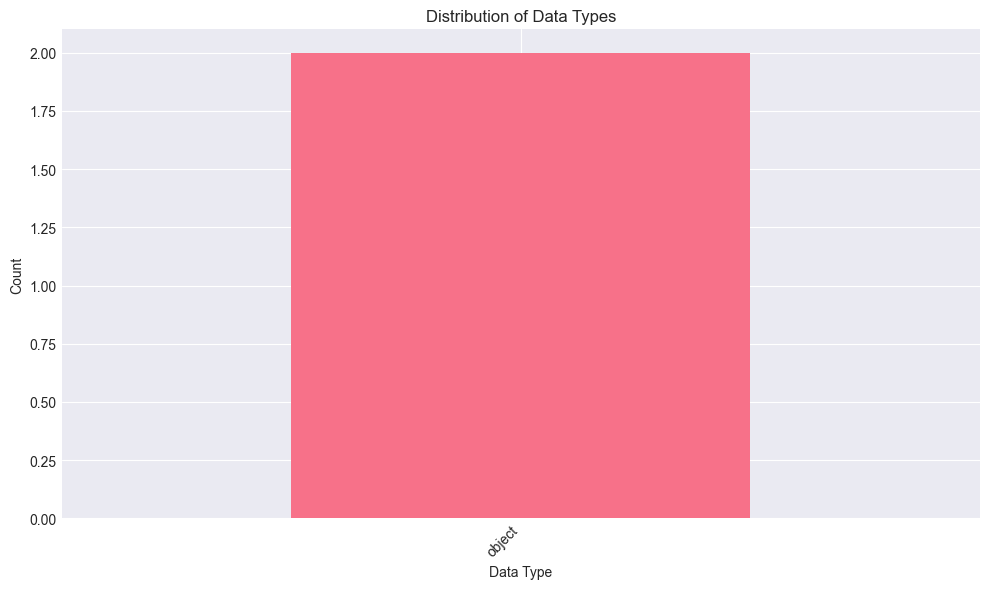

In [16]:
print("=" * 80)
print("DATA TYPES DISTRIBUTION")
print("=" * 80)

dtype_counts = df.dtypes.value_counts()
print(dtype_counts)

# Visualize data types
plt.figure(figsize=(10, 6))
dtype_counts.plot(kind='bar')
plt.xlabel('Data Type')
plt.ylabel('Count')
plt.title('Distribution of Data Types')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 9. Numerical Columns Analysis

In [18]:
# Get numerical columns
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()

if len(numerical_cols) > 0:
    print("=" * 80)
    print(f"NUMERICAL COLUMNS ANALYSIS ({len(numerical_cols)} columns)")
    print("=" * 80)
    print(numerical_cols)
    
    # Distribution plots for numerical columns
    if len(numerical_cols) <= 10:
        fig, axes = plt.subplots(len(numerical_cols), 2, figsize=(15, 5*len(numerical_cols)))
        if len(numerical_cols) == 1:
            axes = axes.reshape(1, -1)
        
        for idx, col in enumerate(numerical_cols):
            # Histogram
            axes[idx, 0].hist(df[col].dropna(), bins=30, edgecolor='black')
            axes[idx, 0].set_title(f'{col} - Distribution')
            axes[idx, 0].set_xlabel(col)
            axes[idx, 0].set_ylabel('Frequency')
            
            # Box plot
            axes[idx, 1].boxplot(df[col].dropna())
            axes[idx, 1].set_title(f'{col} - Box Plot')
            axes[idx, 1].set_ylabel(col)
        
        plt.tight_layout()
        plt.show()
    else:
        print(f"\nToo many numerical columns ({len(numerical_cols)}) to display all distributions.")
        print("Showing first 5 columns only...")
        
        fig, axes = plt.subplots(5, 2, figsize=(15, 25))
        
        for idx, col in enumerate(numerical_cols[:5]):
            # Histogram
            axes[idx, 0].hist(df[col].dropna(), bins=30, edgecolor='black')
            axes[idx, 0].set_title(f'{col} - Distribution')
            axes[idx, 0].set_xlabel(col)
            axes[idx, 0].set_ylabel('Frequency')
            
            # Box plot
            axes[idx, 1].boxplot(df[col].dropna())
            axes[idx, 1].set_title(f'{col} - Box Plot')
            axes[idx, 1].set_ylabel(col)
        
        plt.tight_layout()
        plt.show()
else:
    print("No numerical columns found in the dataset.")

No numerical columns found in the dataset.


## 10. Categorical Columns Analysis

In [19]:
# Get categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

if len(categorical_cols) > 0:
    print("=" * 80)
    print(f"CATEGORICAL COLUMNS ANALYSIS ({len(categorical_cols)} columns)")
    print("=" * 80)
    print(categorical_cols)
    
    # Show value counts for categorical columns with reasonable number of unique values
    for col in categorical_cols:
        unique_count = df[col].nunique()
        if unique_count <= 20:  # Only show if 20 or fewer unique values
            print(f"\n{'='*80}")
            print(f"Value Counts for '{col}' ({unique_count} unique values)")
            print(f"{'='*80}")
            print(df[col].value_counts())
            
            # Visualize
            plt.figure(figsize=(12, 6))
            df[col].value_counts().head(15).plot(kind='bar')
            plt.title(f'Top 15 Values in {col}')
            plt.xlabel(col)
            plt.ylabel('Count')
            plt.xticks(rotation=45, ha='right')
            plt.tight_layout()
            plt.show()
        else:
            print(f"\n'{col}' has {unique_count} unique values (too many to display all)")
            print(f"Top 10 most frequent values:")
            print(df[col].value_counts().head(10))
else:
    print("No categorical columns found in the dataset.")

CATEGORICAL COLUMNS ANALYSIS (2 columns)
['text_id', 'text']

'text_id' has 17275 unique values (too many to display all)
Top 10 most frequent values:
text_id
1138           1
17179871011    1
8589935030     1
8589935145     1
8589935423     1
8589935566     1
8589935710     1
8589935942     1
8589937343     1
874            1
Name: count, dtype: int64

'text' has 17275 unique values (too many to display all)
Top 10 most frequent values:
text
Embark on a seamless journey with our tours from Shanghai, connecting you to China's most iconic cities and nearby treasures. As the bustling transportation hub of Asia, Shanghai is your gateway to a myriad of adventures. Discover the convenience of booking train tickets, flights, and more as you navigate effortlessly through our expertly crafted short trips and excursions. \n Convenient Transportation Hub: Shanghai's strategic location makes it an ideal starting point for your adventures. Benefit from seamless travel connections to China's major 

## 11. Correlation Analysis (for numerical columns)

In [20]:
if len(numerical_cols) > 1:
    print("=" * 80)
    print("CORRELATION ANALYSIS")
    print("=" * 80)
    
    correlation_matrix = df[numerical_cols].corr()
    
    # Display correlation matrix
    display(correlation_matrix)
    
    # Visualize correlation matrix
    plt.figure(figsize=(12, 10))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, 
                square=True, linewidths=1, fmt='.2f')
    plt.title('Correlation Matrix - Numerical Columns')
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns for correlation analysis.")

Not enough numerical columns for correlation analysis.


## 12. Duplicate Records Analysis

In [21]:
print("=" * 80)
print("DUPLICATE RECORDS ANALYSIS")
print("=" * 80)

duplicate_count = df.duplicated().sum()
print(f"\nTotal duplicate rows: {duplicate_count:,}")
print(f"Percentage of duplicates: {(duplicate_count / len(df) * 100):.2f}%")

if duplicate_count > 0:
    print("\nShowing first 5 duplicate rows:")
    display(df[df.duplicated()].head())
else:
    print("\n✓ No duplicate rows found!")

DUPLICATE RECORDS ANALYSIS

Total duplicate rows: 0
Percentage of duplicates: 0.00%

✓ No duplicate rows found!


## 13. Text Length Analysis (for text columns)

TEXT LENGTH ANALYSIS

--------------------------------------------------------------------------------
Column: text_id
--------------------------------------------------------------------------------
Min length: 1
Max length: 11
Mean length: 10.00
Median length: 11.00


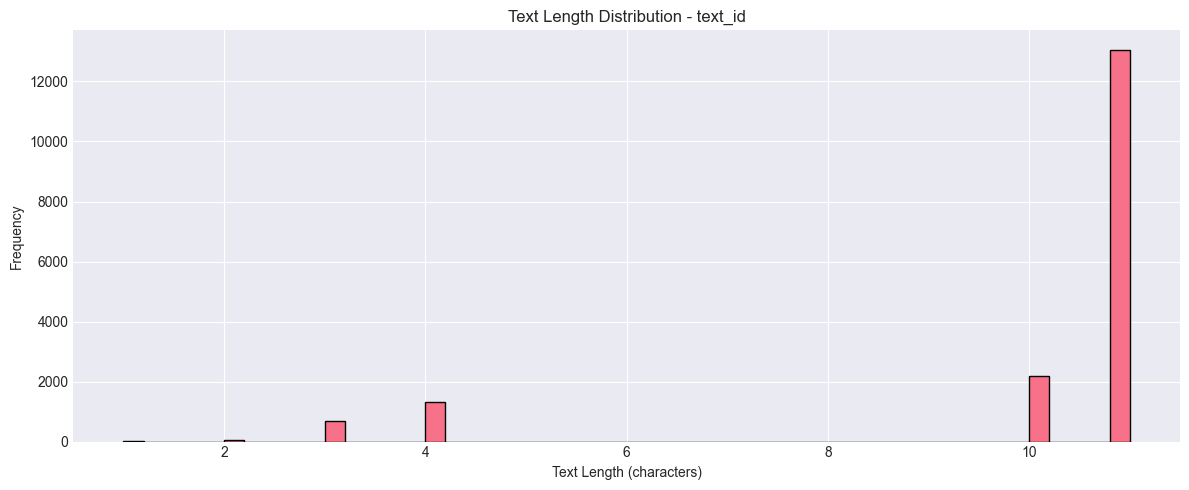


--------------------------------------------------------------------------------
Column: text
--------------------------------------------------------------------------------
Min length: 100
Max length: 5710
Mean length: 2377.61
Median length: 1902.00


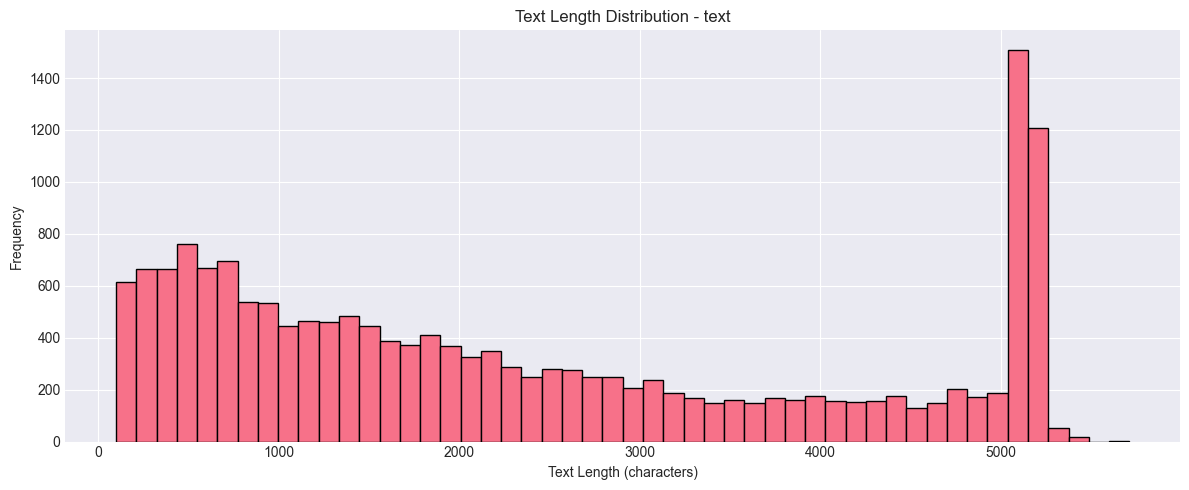

In [22]:
# Analyze text columns
text_cols = [col for col in categorical_cols if df[col].dtype == 'object']

if len(text_cols) > 0:
    print("=" * 80)
    print("TEXT LENGTH ANALYSIS")
    print("=" * 80)
    
    for col in text_cols[:5]:  # Analyze first 5 text columns
        text_lengths = df[col].dropna().astype(str).str.len()
        
        print(f"\n{'-'*80}")
        print(f"Column: {col}")
        print(f"{'-'*80}")
        print(f"Min length: {text_lengths.min()}")
        print(f"Max length: {text_lengths.max()}")
        print(f"Mean length: {text_lengths.mean():.2f}")
        print(f"Median length: {text_lengths.median():.2f}")
        
        # Plot distribution
        plt.figure(figsize=(12, 5))
        plt.hist(text_lengths, bins=50, edgecolor='black')
        plt.title(f'Text Length Distribution - {col}')
        plt.xlabel('Text Length (characters)')
        plt.ylabel('Frequency')
        plt.tight_layout()
        plt.show()

## 14. Summary Report

In [23]:
print("=" * 80)
print("COMPREHENSIVE SUMMARY REPORT")
print("=" * 80)

print(f"\n📊 Dataset Dimensions:")
print(f"   - Rows: {df.shape[0]:,}")
print(f"   - Columns: {df.shape[1]}")
print(f"   - Memory Usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print(f"\n📋 Column Types:")
for dtype, count in df.dtypes.value_counts().items():
    print(f"   - {dtype}: {count} columns")

print(f"\n❓ Missing Values:")
total_missing = df.isnull().sum().sum()
if total_missing > 0:
    print(f"   - Total missing values: {total_missing:,}")
    print(f"   - Percentage: {(total_missing / (df.shape[0] * df.shape[1]) * 100):.2f}%")
else:
    print(f"   - No missing values ✓")

print(f"\n🔄 Duplicate Records:")
if duplicate_count > 0:
    print(f"   - Duplicate rows: {duplicate_count:,} ({(duplicate_count / len(df) * 100):.2f}%)")
else:
    print(f"   - No duplicate rows ✓")

print(f"\n🔢 Numerical Columns: {len(numerical_cols)}")
print(f"📝 Categorical Columns: {len(categorical_cols)}")

print("\n" + "=" * 80)
print("EDA COMPLETE!")
print("=" * 80)

COMPREHENSIVE SUMMARY REPORT

📊 Dataset Dimensions:
   - Rows: 17,275
   - Columns: 2
   - Memory Usage: 97.24 MB

📋 Column Types:
   - object: 2 columns

❓ Missing Values:
   - No missing values ✓

🔄 Duplicate Records:
   - No duplicate rows ✓

🔢 Numerical Columns: 0
📝 Categorical Columns: 2

EDA COMPLETE!
